# Week 7 · Visualisation 1: from tables to pictures

**CM3801 · CMT309/509** · Thursday 19 November 2026

Last week you learnt to load, filter and summarise tables with pandas. A table answers a question exactly, but a reader sees a pattern much faster in a picture. Today you turn tables into charts, and learn to choose the right chart for a question.

By the end of today you can choose a chart type for a question, build and label a matplotlib figure (with subplots), plot straight from a DataFrame with pandas and seaborn, and read a boxplot and explain its outliers.

Today has two teaching parts and a lab: **Hour 1** choosing and building a chart · **Hour 2** DataFrames and seaborn · **Lab** Pokémon statistics and CO₂ emissions.

## Setup

Run this cell first. Today's data is typed into the notebook or comes with seaborn, so there is nothing else to set up.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Hour 1 · Choosing and building a chart

### Two reasons to draw a chart

| | **Exploring** (the chart is for you) | **Communicating** (the chart is for a reader) |
|---|---|---|
| Question | What does the data look like? Is anything wrong or missing? | What is the result of my analysis? |
| Typical charts | scatter plots, correlations, histograms and densities | the one chart that supports your message |
| Polish | quick and rough is fine | labels, units, a title that states the point |

Both happen in every project: you explore **before** modelling, to catch problems, and you communicate **after**, to show what you found. A clear chart can be the difference between a convinced stakeholder and a confused one.

A good communication chart **tells a story** (it supports one line of argument), follows **less is more** (*"Perfection is achieved not when there is nothing more to add, but when there is nothing left to take away"*, Antoine de Saint-Exupéry) and **reduces the reader's effort**: sort the data, use units people understand, use colour to highlight a relationship, and scale text and bars honestly.

### Which chart? Start from the question

| What would you like to show? | Start with |
|---|---|
| **Comparison** among a few items or categories | bar chart |
| **Change over time** | line chart (a column chart for a few periods) |
| **Relationship** between two variables | scatter plot (bubble chart for a third variable) |
| **Distribution** of one variable | histogram, boxplot or density |
| **Composition** (parts of a whole) | stacked bars; a pie only for a simple share of a total |

The chooser below asks the same question in more detail:

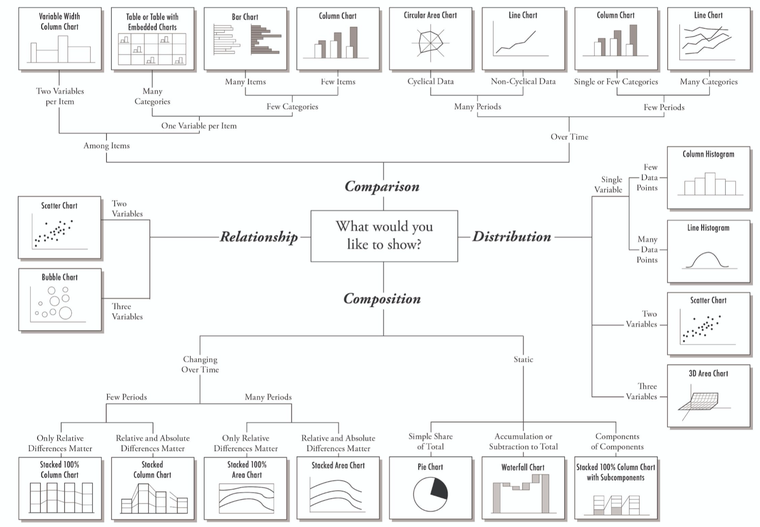

*Chart chooser: Andrew V. Abela, "Chart Suggestions: A Thought-Starter" (extremepresentation.com).*

### What not to do

* **Hard comparisons.** Make clear what is compared and in which unit. Keep comparisons on the **same scale**, and never put two units (°C and mm) on one axis.
* **Neglecting the origin.** A bar's length is its value. If the axis doesn't start at zero, a 40 / 60 split can look like 1 to 10:

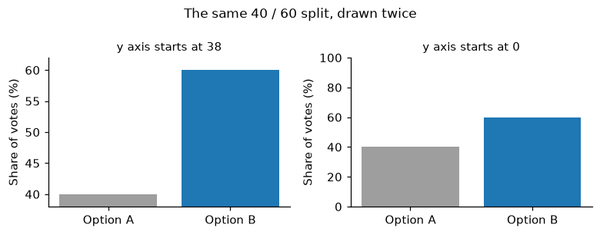

* **Neglecting annotations.** A chart should explain itself at a glance: axis labels with units, a title that says what to see, a legend when there are several series.

### Colour and accessibility

* **Choose the colour map for the data.** *Sequential* for one quantity from low to high (`viridis`, `Blues`); *diverging* for values above and below a meaningful middle, such as 0 (`RdBu`, `coolwarm`); *qualitative* for categories with no order (`tab10`, seaborn's `"colorblind"`).
* About 1 in 12 men and 1 in 200 women have a colour-vision deficiency. Avoid red–green pairs and rainbow maps such as `jet`.
* Never use colour as the **only** cue: add labels, markers or line styles.

### matplotlib: your first plots

**matplotlib** is Python's basic plotting library (gallery: <https://matplotlib.org/stable/gallery/>). seaborn and pandas plotting are built on top of it, so what you learn here works everywhere. In a script you finish with `plt.show()`; in a notebook the plot appears at the end of the cell anyway, and `plt.show()` just keeps the output tidy.

**Predict:** we give `plt.plot` a **single** list of four numbers. What goes on the *x* axis?

In [ ]:
plt.plot([1, 3, 2, 4], "ro")    # "ro" = red circles
plt.show()

With one list, matplotlib uses the positions **0, 1, 2, 3** as *x*. The format string `"ro"` means red (`r`) circles (`o`); `"k*"` would be black stars and `"b-"` a blue line.

In [ ]:
# ✍️ Type along: x and y values, then a title and axis labels; then a bar chart
x = [1, 2, 3, 4]
y = [1, 4, 9, 16]

<details><summary>Code from class</summary>

```python
x = [1, 2, 3, 4]
y = [1, 4, 9, 16]
plt.plot(x, y, marker="o")
plt.title("Squares of the numbers 1 to 4")
plt.xlabel("n")
plt.ylabel("n squared")
plt.show()

# a bar chart: one bar per category
cities = ["Cardiff", "Swansea", "Newport"]
population = [362400, 238500, 159600]       # ONS Census 2021, rounded
plt.bar(cities, population, color="tab:blue")
plt.ylabel("Population")
plt.title("Cardiff is the largest Welsh city")
plt.show()
```

</details>

Bars compare values across **categories** (no time order); lines connect values that follow each other, such as years.

### Real data: Cardiff's climate

The table below holds Cardiff's monthly climate: average and record temperatures (°C) and average rainfall (mm). Monthly averages are for 1981–2010; records run from 1960.

In [ ]:
climate = pd.DataFrame({
    "month":             ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    "record_high":       [13.8, 15.0, 19.5, 24.0, 26.6, 32.1, 32.0, 33.5, 27.0, 24.6, 17.1, 16.7],
    "avg_high":          [8.3, 8.6, 11.1, 13.8, 17.1, 19.8, 21.7, 21.5, 18.8, 14.9, 11.3, 8.7],
    "avg_low":           [2.3, 2.1, 4.0, 5.2, 8.3, 11.0, 13.1, 12.8, 10.5, 7.7, 4.6, 2.6],
    "record_low":        [-10.3, -8.8, -8.1, -4.8, -2.0, 1.0, 5.3, 3.6, 2.4, -2.7, -8.4, -8.8],
    "avg_precipitation": [121.6, 85.2, 89.8, 68.6, 72.3, 66.6, 78.4, 93.4, 94.0, 133.5, 123.4, 125.3],
})
climate.head(3)

**Before we run this:** the next cell draws all five columns on one chart, with no labels. Which of the *don'ts* will it break?

In [ ]:
plt.bar(climate["month"], climate["record_high"], color="r")
plt.bar(climate["month"], climate["record_low"], color="c")
plt.plot(climate["month"], climate["avg_high"], color="k")
plt.plot(climate["month"], climate["avg_low"], color="b")
plt.plot(climate["month"], climate["avg_precipitation"], color="g")
plt.show()

Rainfall (mm) and temperature (°C) share one *y* axis, so the rainfall line dwarfs everything else: a **hard comparison**. There are no labels, units or legend, and red against cyan carries the whole meaning by colour alone.

**Discuss:** you want readers to see how Cardiff's **rainfall** and its **record high temperatures** change through the year. One chart or two? Which chart type for each?

<details><summary>Answer</summary>

Two panels that share the month axis: rainfall as **bars** (an amount per month) and record highs as a **line** with markers (one temperature per month, in order). Each panel gets its own *y* axis with its own unit. A single chart with two *y* axes is possible, but readers easily mix up which line belongs to which axis.

</details>

### Figures and axes

Every matplotlib chart lives in a **figure**, the outer frame, which you can't draw on. Inside it are one or more **axes**: the areas where data is drawn. When you call `plt.plot` or `plt.bar`, matplotlib draws on the **current** axes, which is why the cell above piled five series into one picture.

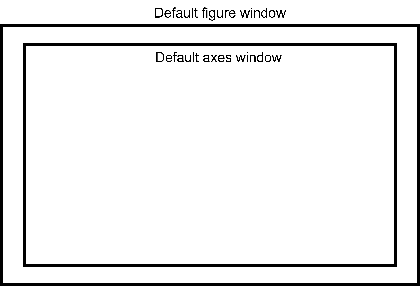

`fig, ax = plt.subplots()` creates a figure **and** gives you a name for each axes, so you decide where each series goes:

| `fig, ax = plt.subplots(1, 2)` | `fig, ax = plt.subplots(2, 2, figsize=(10, 5))` |
|---|---|
| ![a figure holding ax[0] and ax[1] side by side](attachment:subplots_1x2.png) | ![a 10 by 5 figure holding ax[0,0] to ax[1,1]](attachment:subplots_2x2.png) |

With one row or one column, `ax` is a 1-D array (`ax[0]`, `ax[1]`); with a grid it is 2-D (`ax[1, 0]`). `figsize` is (width, height) in inches. On an axes, the `plt.` functions get a `set_` prefix: `plt.title` → `ax.set_title`, `plt.xlabel` → `ax.set_xlabel`.
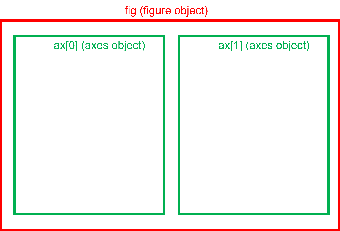
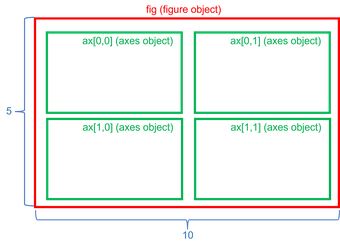

In [ ]:
# ✍️ Type along: rainfall and record highs in two panels that share the month axis
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

<details><summary>Code from class</summary>

```python
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax[0].bar(climate["month"], climate["avg_precipitation"], color="tab:blue")
ax[0].set_ylabel("Average rainfall (mm)")
ax[0].set_title("Cardiff: wettest in autumn and winter, record heat in summer")

ax[1].plot(climate["month"], climate["record_high"], marker="o", color="tab:red")
ax[1].set_ylabel("Record high (°C)")
ax[1].set_xlabel("Month")
plt.show()
```

</details>

`sharex=True` gives both panels the same months, so a reader can look straight down from a bar to the temperature of the same month.

**Quick check:** in the figure above, where does the title *"Cardiff: wettest in autumn…"* live?
1. on the figure, 2. on the top axes, 3. on both panels.

<details><summary>Answer</summary>

**2.** `ax[0].set_title(...)` puts a title on **one axes**. A title over the whole figure is `fig.suptitle(...)`.

</details>

**Your turn:** this chart puts average high temperature (°C) and rainfall (mm) on **one** axes. Fix it: draw them **side by side** in two panels (1 row, 2 columns), temperature as a line and rainfall as bars, each with a *y* label that includes the unit, and one title for the whole figure.

In [ ]:
plt.plot(climate["month"], climate["avg_high"])
plt.plot(climate["month"], climate["avg_precipitation"])
plt.show()
# your code here

<details><summary>Answer</summary>

```python
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(climate["month"], climate["avg_high"], marker="o", color="tab:red")
ax[0].set_ylabel("Average high (°C)")
ax[1].bar(climate["month"], climate["avg_precipitation"], color="tab:blue")
ax[1].set_ylabel("Average rainfall (mm)")
fig.suptitle("Cardiff: monthly temperature and rainfall")
plt.show()
```

`sharey=True` would be wrong here: the two panels have **different units**, so each needs its own *y* axis.

</details>

### Takeaways: choosing and building a chart

* Start from the **question**: comparison → bars, time → lines, relationship → scatter, distribution → histogram or boxplot.
* Avoid the don'ts: one unit per axis, bars start at zero, label everything with units.
* Pick a colour map that fits the data, and never rely on colour alone.
* The **figure** is the frame; you draw on **axes**. `fig, ax = plt.subplots(rows, cols)` gives you control over each panel.

## Hour 2 · DataFrames and seaborn

### Plotting straight from a DataFrame

A DataFrame knows its own columns, so pandas can plot them for you: `df.plot()` draws **one line per column** against the index (or against a column you name with `x=`). It returns the matplotlib axes, so everything from Hour 1 still works.

**Predict:** how many lines will this draw, and what will the *x* axis show?

In [ ]:
ax = climate.plot(x="month", y=["avg_high", "avg_low"], marker="o")
ax.set_ylabel("Temperature (°C)")
plt.show()

Two lines, one per column in `y`, with the month names on the *x* axis and a **legend** for free (pandas uses the column names).

From now on we use a bigger table: **`tips`**, one row per restaurant bill, with the bill, the tip, the day, the time and the party. It is one of seaborn's example datasets, downloaded the first time you load it.

In [ ]:
tips = sns.load_dataset("tips")
print(tips.shape)
tips.head(3)

In [ ]:
# ✍️ Type along: the distribution of total bills, as a histogram from pandas

<details><summary>Code from class</summary>

```python
ax = tips["total_bill"].plot(kind="hist", bins=20, edgecolor="white")
ax.set_xlabel("Total bill ($)")
ax.set_ylabel("Number of bills")
ax.set_title("Most bills are between $10 and $25; a few are much larger")
plt.show()
```

</details>

A histogram counts how many values fall into each **bin**. This one is **right-skewed**: a long tail of large bills. Try `bins=5` and `bins=50`: too few bins hide the shape, too many make it noisy.

### seaborn: statistical plots in one line

**seaborn** (`import seaborn as sns`) is built on matplotlib and designed for **statistical** plots of DataFrames: you name the DataFrame and the columns, and seaborn does the grouping, colouring and legend.

| matplotlib | seaborn |
|---|---|
| low-level: you draw every element | high-level: one call per statistical plot |
| manual styling | themes and colour palettes built in |
| fine-grained control | quick plots with smart defaults |

Use seaborn for fast, statistically meaningful plots, and matplotlib (`ax.set_…`) to fine-tune them.

In [ ]:
# ✍️ Type along: does a bigger bill get a bigger tip? Add a regression line, then split by smoker

<details><summary>Code from class</summary>

```python
sns.lmplot(data=tips, x="total_bill", y="tip")
plt.show()

sns.lmplot(data=tips, x="total_bill", y="tip", hue="smoker")
plt.show()
```

</details>

`lmplot` draws a scatter plot plus a fitted straight line with a shaded uncertainty band. `hue=` splits the data by a category: **one colour and one line per group**. Here the smokers' line is flatter: their tips grow less with the bill.

### Boxplots: a distribution in five numbers

A **boxplot** (box-and-whisker plot) summarises a numerical variable by its quartiles, so you can compare **location**, **spread** and **skewness** across groups at a glance.

* The line in the box is the **median** ($Q_2$, 50 %); the box runs from the **lower quartile** $Q_1$ (25 %) to the **upper quartile** $Q_3$ (75 %).
* The **interquartile range** is $IQR = Q_3 - Q_1$: the middle half of the data.
* Points below $Q_1 - 1.5 \times IQR$ or above $Q_3 + 1.5 \times IQR$ are drawn separately as **outliers**.
* The whiskers reach the smallest and largest values **inside** those limits. In the figure they are labelled $Q_0$ and $Q_4$: the minimum and maximum once the outliers are set aside.

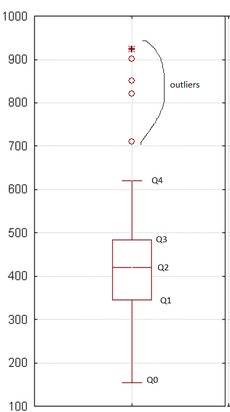

**Predict:** on which day do the total bills have the **widest spread**? Look at the box heights, not the whiskers.

In [ ]:
sns.boxplot(data=tips, x="day", y="total_bill")
plt.ylabel("Total bill ($)")
plt.show()
tips.groupby("day", observed=True)["total_bill"].describe().round(1)

**Saturday** has the tallest box ($IQR = 24.7 - 13.9 \approx 10.8$), just ahead of Sunday; **Thursday** has the narrowest. Weekend bills are also higher (larger medians), and every day has a few outliers above the upper whisker. (`observed=True` keeps only the days that occur; `day` is stored as a category.)

**Your turn:** draw a boxplot of the **tip** for each **time** of day (Lunch, Dinner). Label the *y* axis with its unit and give the chart a title. Then add `hue="smoker"` and see what changes.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
sns.boxplot(data=tips, x="time", y="tip", hue="smoker")
plt.ylabel("Tip ($)")
plt.title("Tips are a little higher at dinner")
plt.show()
```

With `hue`, each time of day gets **two** boxes side by side, one per group, and seaborn adds the legend.

</details>

**Discuss:** when can a boxplot **mislead**? Think about what it does *not* show. Then run the cell below.

In [ ]:
tips["day"].value_counts()

<details><summary>Answer</summary>

* It hides **how many** values are in each box: Friday's box is drawn from only 19 bills, Saturday's from 87, yet they look equally solid.
* It hides the **shape** inside the box: two clusters (a bimodal distribution) and one smooth hump can give the same box.
* With very large datasets, the $1.5 \times IQR$ rule flags thousands of ordinary values as "outliers".

Fixes: report the counts, or draw the points on top (`sns.stripplot`, in the optional section below).

</details>

### Heatmaps: a table of numbers as colours

A **heatmap** colours each cell of a table. Its most common use is a **correlation matrix**: `df.corr()` gives the correlation (from −1 to +1) between every pair of numerical columns, as you computed with numpy in Week 5.

**Before we run this:** the five numerical columns of `climate` describe the same twelve months. Which pairs do you expect to be strongly correlated, and which negatively?

In [ ]:
corr = climate.drop(columns="month").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Cardiff monthly climate: correlations")
plt.show()

All four temperature columns move together (close to +1, dark red); rainfall is **negatively** correlated with temperature (about −0.5, blue): in Cardiff the colder months are the wetter ones. With only twelve months, treat these numbers as a description, not as proof.

**Quick check:** why is a **diverging** colour map (`RdBu_r`) with `vmin=-1, vmax=1` the right choice here, rather than `viridis`?

<details><summary>Answer</summary>

Correlation has a meaningful **middle**, 0 (no linear relationship). A diverging map shows positive and negative values in two different colours with white at 0, and fixing the range to −1…+1 keeps the colours comparable between heatmaps. A sequential map such as `viridis` would make −0.5 look like "a bit less than 1" instead of "the opposite direction".

</details>

### Takeaways: DataFrames and seaborn

* `df.plot(...)` and `df["col"].plot(kind="hist")` plot straight from pandas and return a matplotlib axes.
* seaborn makes statistical plots from a DataFrame in one call: `sns.lmplot(..., hue=...)`, `sns.boxplot`, `sns.heatmap`.
* A boxplot shows the median, the quartiles and the outliers beyond $1.5 \times IQR$, but not the group sizes or the shape inside the box.
* A correlation heatmap needs a diverging colour map centred on 0.

## Transition to the lab

**You now know** how to choose a chart for a question, build and label it with matplotlib (`fig, ax = plt.subplots`), and plot straight from DataFrames with pandas and seaborn.

**The lab** (`W07a_lab_student.ipynb`, two hours) has two parts:
* **Part A · Pokémon statistics:** histograms in one figure, a scatter plot of one generation, a bar chart of a group mean, and a correlation heatmap.
* **Part B · CO₂ emissions since 1950:** line charts for several countries, small multiples, total versus per-person emissions, and a correlation heatmap.

Each part ends with the question you should always ask of a chart: **what would you tell a reader?**

## Week 7 takeaways

* Choose the chart from the question: comparison, change over time, relationship, distribution or composition.
* One unit per axis; bars start at zero; label axes with units; never rely on colour alone.
* matplotlib draws on **axes** inside a **figure**; `fig, ax = plt.subplots(...)` gives you each panel.
* pandas and seaborn plot straight from a DataFrame; seaborn adds statistics (regression lines, boxplots, heatmaps).
* A boxplot summarises a distribution in five numbers; outliers lie beyond $1.5 \times IQR$.

## Where next

**Week 8 · Text Processing.** So far your data has been numbers in tables. Next week the data is **text**: you will find patterns with regular expressions and process documents with NLTK, building on the pandas `.str` methods from Week 6. The charts you made today will help you show what you find in a corpus.

Before next week: rerun this notebook top to bottom and finish any *Your turn* you skipped.

## Optional: explore after class

**Saving a figure.** `fig.savefig` writes the figure to a file (in Colab, look in the *Files* panel). `dpi` sets the resolution.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(climate["month"], climate["avg_precipitation"], color="tab:blue")
ax.set_ylabel("Average rainfall (mm)")
fig.savefig("cardiff_rainfall.png", dpi=150, bbox_inches="tight")
plt.show()

**Scatter plots with size and colour.** `plt.scatter` can map two more variables to marker **size** (`s=`) and **colour** (`c=`). Here with random numbers (`rng` from Week 5):

In [ ]:
rng = np.random.default_rng(0)
x, y = rng.random(50), rng.random(50)
plt.scatter(x, y, s=(30 * rng.random(50)) ** 2, c=rng.random(50), alpha=0.6, cmap="viridis")
plt.colorbar(label="a third variable")
plt.show()

**Boxplot variants.** A **strip plot** draws every value, so you see the group sizes a boxplot hides. A **point plot** shows each group's mean with an error bar. A **boxenplot** shows more quantiles than a boxplot and suits very large datasets, such as 53,940 diamonds.

In [ ]:
sns.boxplot(data=tips, x="day", y="total_bill", color="white")
sns.stripplot(data=tips, x="day", y="total_bill", alpha=0.5)
plt.show()
sns.pointplot(data=tips, x="day", y="tip")
plt.show()

In [ ]:
diamonds = sns.load_dataset("diamonds")
order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
sns.boxenplot(data=diamonds, x="clarity", y="carat", order=order)
plt.show()

**More chart types.** The galleries at <https://python-graph-gallery.com/> and <https://seaborn.pydata.org/examples/> show a code example for each chart; there are also libraries for interactive charts (for example Bokeh and Altair).

## Credits

* Chart chooser: Andrew V. Abela, *Chart Suggestions: A Thought-Starter*, extremepresentation.com.
* Cardiff climate table: Met Office climate averages (1981–2010) and records, as compiled in the climate table of the Wikipedia article *Cardiff*.
* Population figures: Office for National Statistics, Census 2021 (rounded).
* `tips`: restaurant tips recorded by one waiter, from P. G. Bryant and M. A. Smith, *Practical Data Analysis: Case Studies in Business Statistics* (1995); `diamonds`: from the ggplot2 R package. Both are distributed with seaborn's example datasets (<https://github.com/mwaskom/seaborn-data>).